# Medical Cost Prediction

Predict the recorded medical charges in `insurance.csv` using age, sex, BMI, children, smoker status and region.

Dataset: [Medical Cost Personal Datasets on Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance).

Work through the notebook in order. Models train on the training set, small parameter searches use the validation set, and the final model is evaluated on the test set. Run the notebook from the `mock/regression` folder.

## 1. Objective and evaluation

Use RMSE in dollars to compare models. Also report MAE, R² and mean prediction error. RMSE emphasizes large errors. MAE describes the average absolute error. Reserve the test set until model selection is complete.

## 2. Setup

Import the libraries, set the random seed and create a folder for the plots.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

SEED = 42
np.random.seed(SEED)
FIG = "outputs/figures/"
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RAW_NUMERIC = ["age", "bmi", "children"]
TARGET = "charges"

Matplotlib is building the font cache; this may take a moment.


## 3. Load and inspect the data

Inspect the columns, missing values and duplicates. Remove exact duplicate rows from the modeling data. Keep the downloaded CSV unchanged. People can share the same demographic attributes, so matching predictors alone do not establish a duplicate person.

In [2]:
df = pd.read_csv("insurance.csv")
print(df.shape)
print(df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())
display(df.head())
display(df.dtypes)

df = df.drop_duplicates().copy()
print("Rows used:", len(df))

(1338, 7)
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Exact duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Rows used: 1337


## 4. Train, validation and test split

Use approximately 60% of records for training, 20% for validation and 20% for testing. Use training data for EDA. This is a random benchmark split. The dataset does not supply identifiers or dates for customer-level or future-period validation.

In [3]:
train_val, test = train_test_split(df, test_size=0.20, random_state=SEED)
train, val = train_test_split(train_val, test_size=0.25, random_state=SEED)

train = train.copy()
val = val.copy()
test = test.copy()

y_train = train["charges"]
y_val = val["charges"]
y_test = test["charges"]
train_eda = train.copy()

print("Training rows:", len(train))
print("Validation rows:", len(val))
print("Test rows:", len(test))

Training rows: 801
Validation rows: 268
Test rows: 268


## 5. Exploratory data analysis

Look at the target distribution, large charges and feature relationships using training data. Smoker status and BMI may interact. These associations describe this dataset and do not establish causal effects.

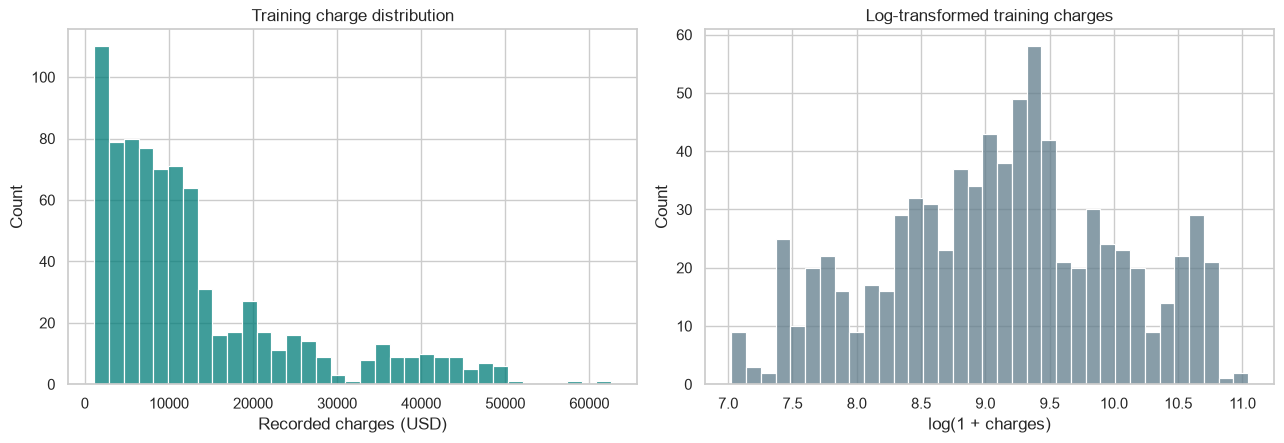

,Training charges
count,801.000000
mean,13286.258689
std,11924.717614
min,1121.873900
25%,4830.630000
50%,9617.662450
75%,17178.682400
max,62592.873090


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sns.histplot(y_train, bins=35, ax=axes[0], color="#007C78")
axes[0].set(xlabel="Recorded charges (USD)", title="Training charge distribution")
sns.histplot(np.log1p(y_train), bins=35, ax=axes[1], color="#607C8B")
axes[1].set(xlabel="log(1 + charges)", title="Log-transformed training charges")
fig.tight_layout()
fig.savefig(FIG + "01_target_distributions.png", dpi=180, bbox_inches="tight")
plt.show()
display(y_train.describe().to_frame("Training charges"))

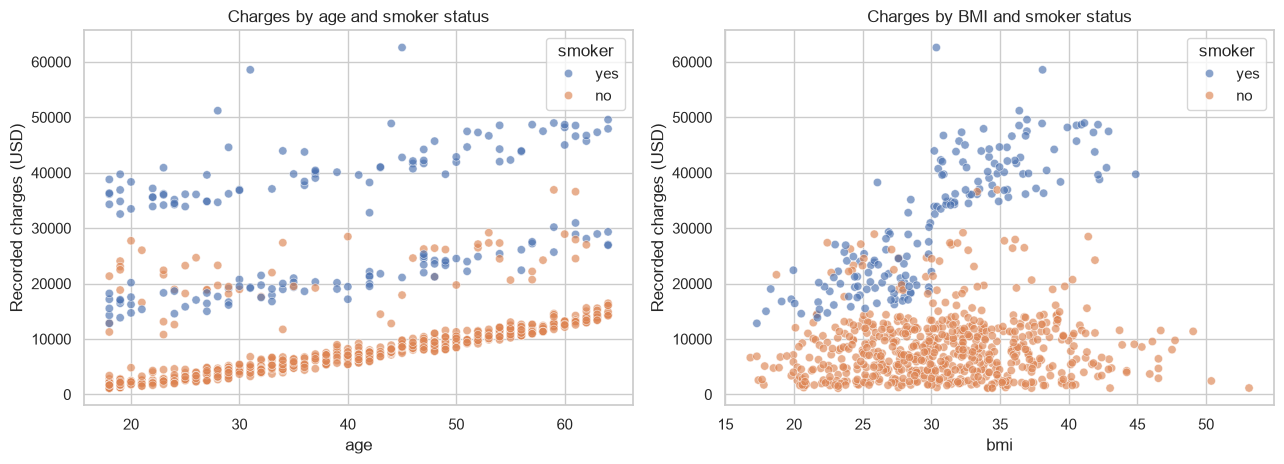

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=train_eda, x="age", y="charges", hue="smoker", alpha=.65, ax=axes[0])
sns.scatterplot(data=train_eda, x="bmi", y="charges", hue="smoker", alpha=.65, ax=axes[1])
axes[0].set_title("Charges by age and smoker status")
axes[1].set_title("Charges by BMI and smoker status")
for ax in axes: ax.set_ylabel("Recorded charges (USD)")
fig.tight_layout()
fig.savefig(FIG + "02_age_bmi_associations.png", dpi=180, bbox_inches="tight")
plt.show()

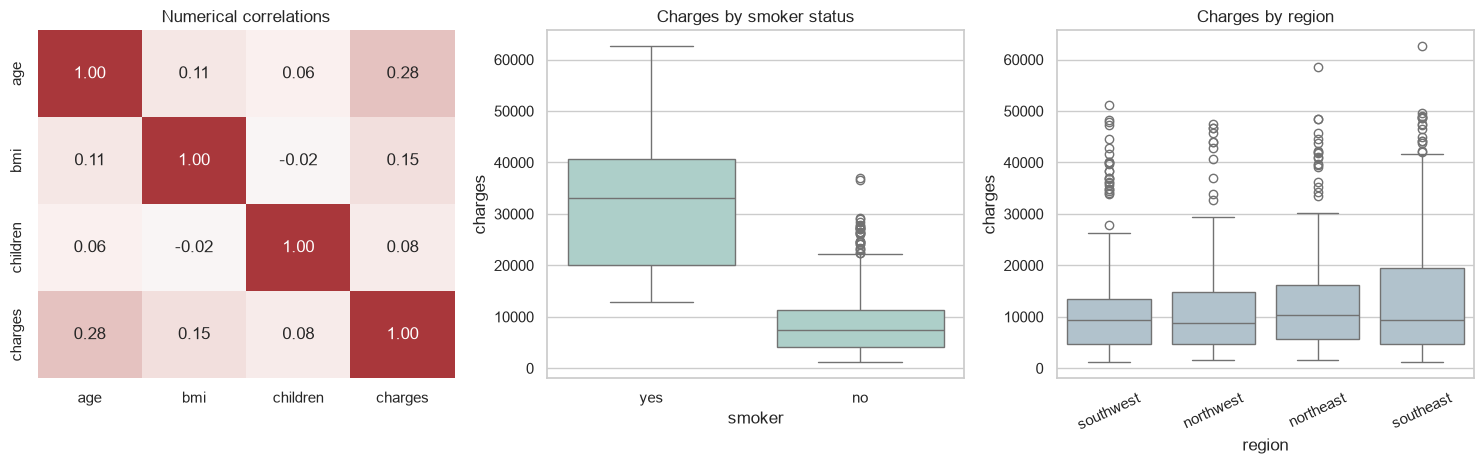

,Rows,Mean,Median
smoker,,,
no,631,8446.699893,7371.77200
yes,170,31249.562223,33131.63787


,Rows,Mean,Median
region,,,
northeast,186,13551.932272,10284.342375
northwest,200,11819.132917,8702.210250
southeast,217,14913.547843,9386.161300
southwest,198,12735.188597,9445.358500


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
sns.heatmap(train_eda[RAW_NUMERIC+[TARGET]].corr(), annot=True, fmt=".2f", center=0,
            cmap="vlag", ax=axes[0], cbar=False)
axes[0].set_title("Numerical correlations")
sns.boxplot(data=train_eda, x="smoker", y="charges", ax=axes[1], color="#A8D4CC")
axes[1].set_title("Charges by smoker status")
sns.boxplot(data=train_eda, x="region", y="charges", ax=axes[2], color="#ADC3D0")
axes[2].set_title("Charges by region")
axes[2].tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIG + "03_correlations_and_categories.png", dpi=180, bbox_inches="tight")
plt.show()
display(train_eda.groupby("smoker").charges.agg(Rows="size", Mean="mean", Median="median"))
display(train_eda.groupby("region").charges.agg(Rows="size", Mean="mean", Median="median"))

The charge distribution is skewed. A log transform can help some models, but it changes the errors emphasized during fitting. Compare its predictions in dollars. Read the subgroup averages together with their counts.

## 6. Feature engineering and preprocessing

Add age squared and smoker interactions. Encode categories with `pd.get_dummies`. Use the training columns for all partitions. Fit the scaler on training data and apply it to validation and test data. Linear models, KNN and MLP use scaled inputs. Trees use the encoded inputs directly.

In [7]:
for data in [train, val, test]:
    data["age_squared"] = data["age"] ** 2
    data["smoker_bmi"] = (data["smoker"] == "yes").astype(int) * data["bmi"]
    data["smoker_age"] = (data["smoker"] == "yes").astype(int) * data["age"]

X_train = pd.get_dummies(train.drop(columns="charges"), drop_first=True, dtype=int)
X_val = pd.get_dummies(val.drop(columns="charges"), drop_first=True, dtype=int)
X_test = pd.get_dummies(test.drop(columns="charges"), drop_first=True, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(X_train.columns.tolist())

['age', 'bmi', 'children', 'age_squared', 'smoker_bmi', 'smoker_age', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


All category levels in this dataset appear in the training partition. The encoded columns therefore use the same reference categories in each partition. For new data with missing or unseen category levels, define the category levels explicitly before encoding.

## 7. Baseline and metrics

Use the training mean as the constant baseline for squared error. The median provides an MAE reference. The helper below only calculates metrics and saves predictions. Fitting remains visible in each model cell.

In [8]:
results = {}
predictions = {}

def evaluate(name, actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    rmse = root_mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    bias = np.mean(predicted - actual)
    results[name] = [rmse, mae, r2, bias]
    predictions[name] = predicted
    print(name, "RMSE:", round(rmse, 2), "MAE:", round(mae, 2), "R2:", round(r2, 3))

mean_prediction = np.full(len(y_val), y_train.mean())
median_prediction = np.full(len(y_val), y_train.median())
evaluate("Mean baseline", y_val, mean_prediction)
evaluate("Median baseline", y_val, median_prediction)

Mean baseline RMSE: 11041.43 MAE: 8555.46 R2: -0.009
Median baseline RMSE: 11308.32 MAE: 7632.06 R2: -0.058


## 8. Linear regression

OLS fits an additive relationship in the supplied features. The interactions allow different fitted age and BMI associations for smoker groups. Its strengths are transparency and low computational cost. Its limitations include sensitivity to unusual observations and the need to specify nonlinear structure explicitly.

In [9]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_val_scaled)
evaluate("Linear regression", y_val, pred_lr)

Linear regression RMSE: 5037.49 MAE: 2955.44 R2: 0.79


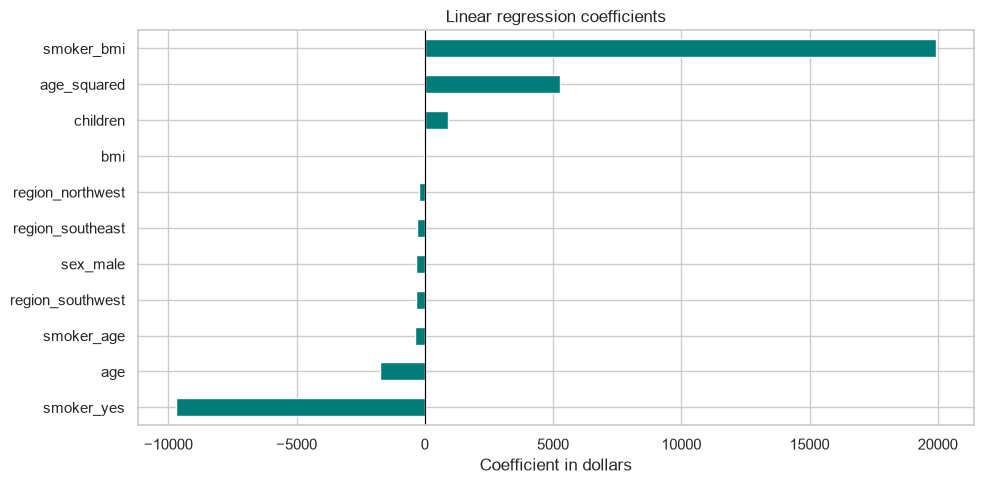

In [10]:
coefficients = pd.Series(lr.coef_, index=X_train.columns)
coefficients = coefficients.sort_values()
coefficients.plot.barh(color="#007C78")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Linear regression coefficients")
plt.xlabel("Coefficient in dollars")
plt.tight_layout()
plt.savefig(FIG + "04_linear_coefficients.png", dpi=180, bbox_inches="tight")
plt.show()

Every encoded input is standardized, including the dummy variables. A coefficient describes a one-standard-deviation change in that input while other terms stay fixed. Interactions and correlated inputs make individual coefficients harder to interpret.

## 9. Ridge, Lasso and Elastic Net

Ridge shrinks coefficients using an L2 penalty. Lasso uses L1 and can set coefficients to zero. Elastic Net combines both penalties. Try three strengths for each model and keep the one with the lowest validation RMSE. Strong shrinkage can reduce variance but introduce bias.

In [11]:
best_rmse = float("inf")
for alpha in [0.1, 1, 10]:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_val_scaled)
    rmse = root_mean_squared_error(y_val, pred)
    print("alpha:", alpha, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        ridge = model

print("Selected alpha:", ridge.alpha)
evaluate("Ridge", y_val, ridge.predict(X_val_scaled))

alpha: 0.1 RMSE: 5033.23
alpha: 1 RMSE: 5000.88
alpha: 10 RMSE: 4936.85
Selected alpha: 10
Ridge RMSE: 4936.85 MAE: 2882.99 R2: 0.798


In [12]:
best_rmse = float("inf")
for alpha in [1, 10, 100]:
    model = Lasso(alpha=alpha, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_val_scaled)
    rmse = root_mean_squared_error(y_val, pred)
    print("alpha:", alpha, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        lasso = model

print("Selected alpha:", lasso.alpha)
evaluate("Lasso", y_val, lasso.predict(X_val_scaled))

alpha: 1 RMSE: 5034.26
alpha: 10 RMSE: 5009.71
alpha: 100 RMSE: 4964.28
Selected alpha: 100
Lasso RMSE: 4964.28 MAE: 2902.79 R2: 0.796


In [13]:
best_rmse = float("inf")
for alpha in [1, 10, 100]:
    model = ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_val_scaled)
    rmse = root_mean_squared_error(y_val, pred)
    print("alpha:", alpha, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        elastic = model

print("Selected alpha:", elastic.alpha)
evaluate("Elastic Net", y_val, elastic.predict(X_val_scaled))

alpha: 1 RMSE: 5750.21
alpha: 10 RMSE: 8375.7
alpha: 100 RMSE: 10625.59
Selected alpha: 1
Elastic Net RMSE: 5750.21 MAE: 4011.6 R2: 0.726


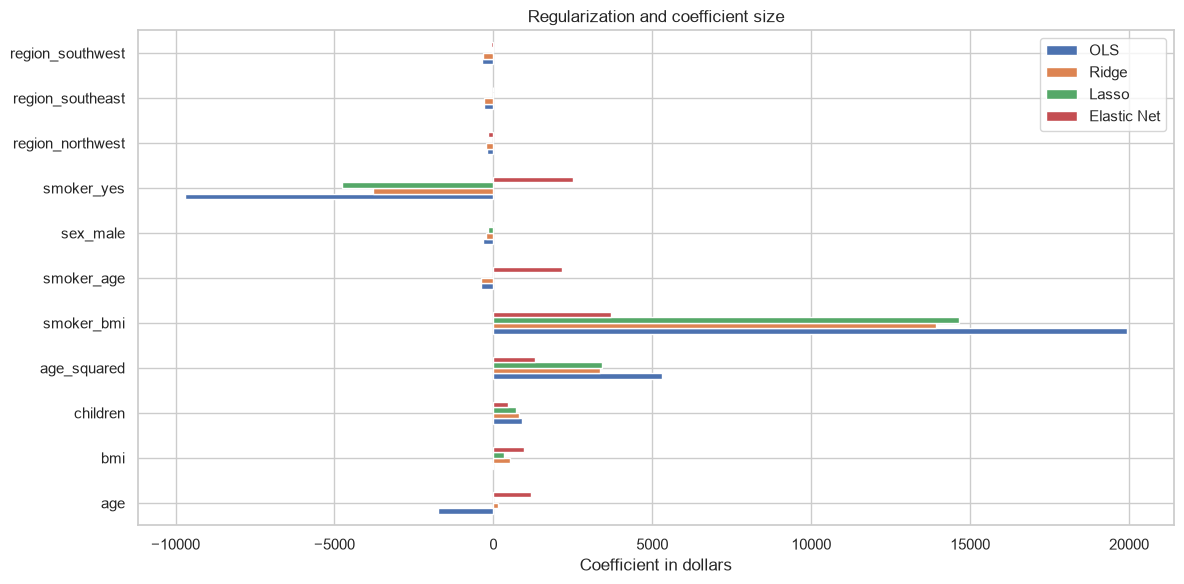

Zero coefficients:
OLS            0
Ridge          0
Lasso          3
Elastic Net    0
dtype: int64


In [14]:
coefficient_comparison = pd.DataFrame({
    "OLS": lr.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "Elastic Net": elastic.coef_,
}, index=X_train.columns)

coefficient_comparison.plot.barh(figsize=(12, 6))
plt.title("Regularization and coefficient size")
plt.xlabel("Coefficient in dollars")
plt.tight_layout()
plt.savefig(FIG + "05_regularized_coefficients.png", dpi=180, bbox_inches="tight")
plt.show()
print("Zero coefficients:")
print((coefficient_comparison == 0).sum())

## 10. K-nearest neighbors

KNN averages nearby training observations. Scaling matters because distance depends on units. It is easy to understand, but irrelevant inputs can dilute similarity and prediction gets slower as training data grow.

In [15]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)
pred_knn = knn.predict(X_val_scaled)
evaluate("KNN", y_val, pred_knn)

KNN RMSE: 5263.0 MAE: 3096.72 R2: 0.771


## 11. Multilayer perceptron

MLP learns nonlinear relationships. It needs scaling and regularization and is less interpretable than OLS. Divide the training target by 10,000 to help optimization, then multiply predictions by 10,000 to return to dollars. This is a fixed unit conversion, not a learned target transformation.

In [16]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    alpha=0.001,
    max_iter=1000,
    early_stopping=True,
    n_iter_no_change=20,
    random_state=SEED,
)
mlp.fit(X_train_scaled, y_train / 10000)
pred_mlp = mlp.predict(X_val_scaled) * 10000
evaluate("MLP", y_val, pred_mlp)

MLP RMSE: 5125.23 MAE: 2950.09 R2: 0.783


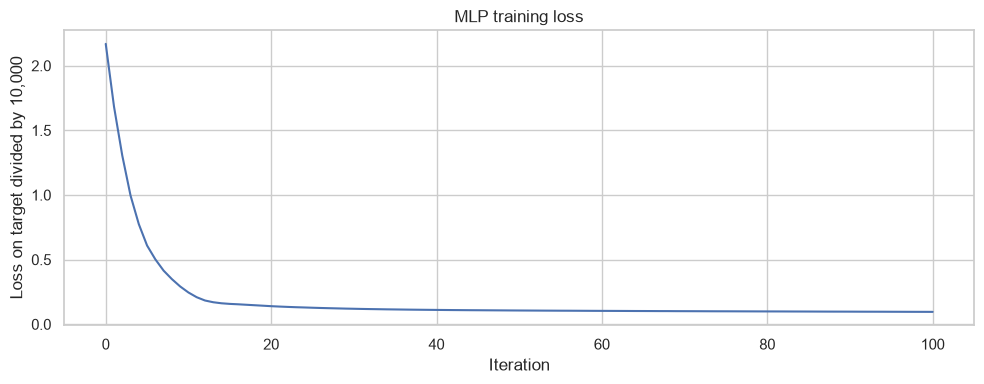

Iterations: 101


In [17]:
plt.figure(figsize=(10, 4))
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss")
plt.xlabel("Iteration")
plt.ylabel("Loss on target divided by 10,000")
plt.tight_layout()
plt.savefig(FIG + "06_mlp_training.png", dpi=180, bbox_inches="tight")
plt.show()
print("Iterations:", mlp.n_iter_)

## 12. Random Forest

Random Forest averages randomized trees and captures interactions without scaling. It can use substantial memory and extrapolates poorly beyond the training response range.

In [18]:
forest = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=2,
)
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_val)
evaluate("Random Forest", y_val, pred_forest)

Random Forest RMSE: 4980.26 MAE: 2879.96 R2: 0.795


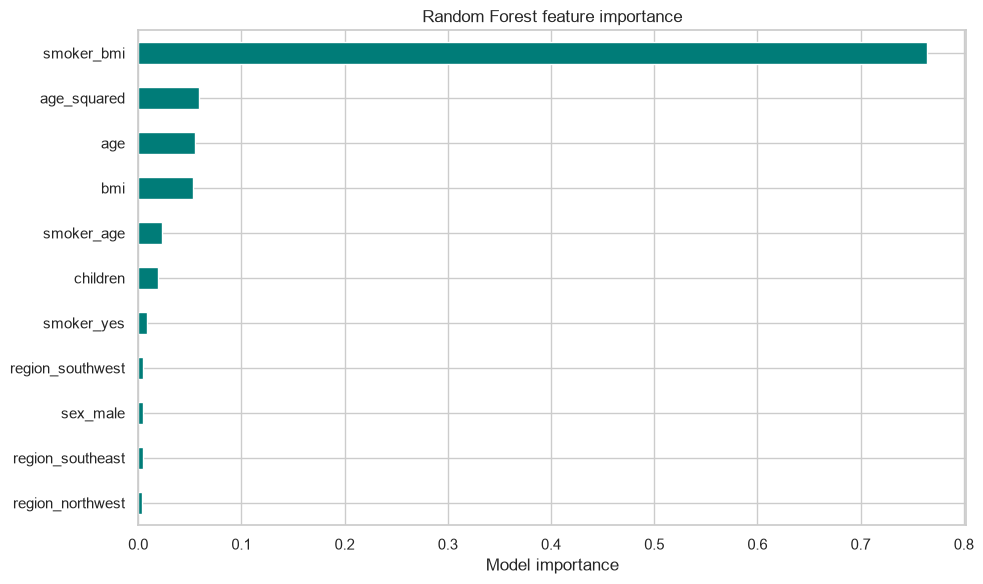

In [19]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance.sort_values().plot.barh(color="#007C78", figsize=(10, 6))
plt.title("Random Forest feature importance")
plt.xlabel("Model importance")
plt.tight_layout()
plt.savefig(FIG + "07_forest_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 13. XGBoost

XGBoost adds trees sequentially. Learning rate, depth and tree count affect its bias and variance. Flexible trees can overfit a small dataset.

In [20]:
xgb = XGBRegressor(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=2,
)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_val)
evaluate("XGBoost", y_val, pred_xgb)

XGBoost RMSE: 4906.92 MAE: 2729.23 R2: 0.801


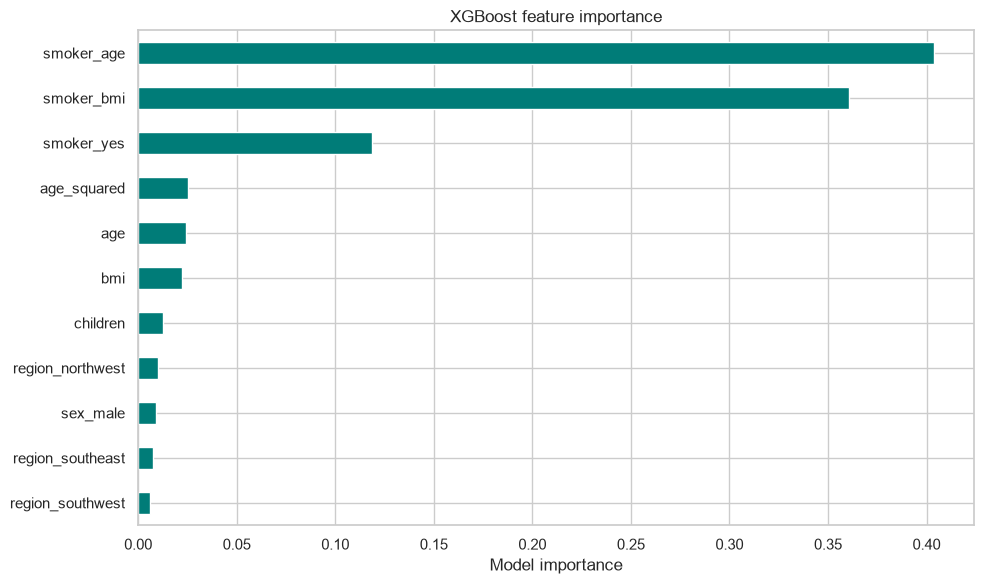

In [21]:
importance = pd.Series(xgb.feature_importances_, index=X_train.columns)
importance.sort_values().plot.barh(color="#007C78", figsize=(10, 6))
plt.title("XGBoost feature importance")
plt.xlabel("Model importance")
plt.tight_layout()
plt.savefig(FIG + "08_xgb_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 14. CatBoost

CatBoost also learns tree interactions. Here it uses the same one-hot encoded inputs as the other tree models. Native categorical support is useful in other settings, but is not necessary for these few low-cardinality fields.

In [22]:
cat = CatBoostRegressor(
    iterations=400,
    depth=4,
    learning_rate=0.04,
    random_seed=SEED,
    thread_count=2,
    verbose=False,
    allow_writing_files=False,
)
cat.fit(X_train, y_train)
pred_cat = cat.predict(X_val)
evaluate("CatBoost", y_val, pred_cat)

CatBoost RMSE: 4732.78 MAE: 2672.06 R2: 0.815


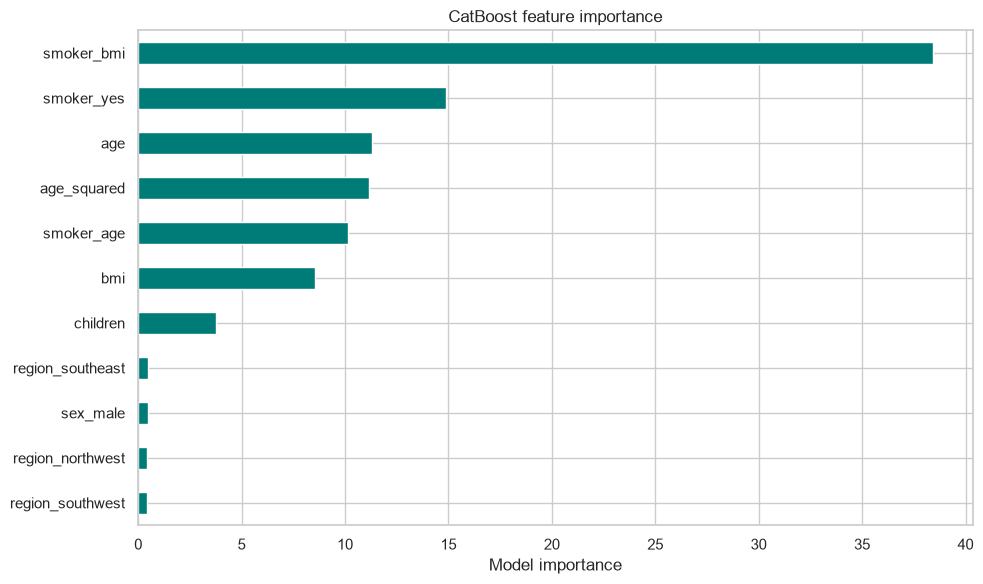

In [23]:
importance = pd.Series(cat.feature_importances_, index=X_train.columns)
importance.sort_values().plot.barh(color="#007C78", figsize=(10, 6))
plt.title("CatBoost feature importance")
plt.xlabel("Model importance")
plt.tight_layout()
plt.savefig(FIG + "09_cat_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 15. LightGBM

LightGBM uses histogram splits and flexible leaf growth. Leaf count and minimum leaf size help control overfitting, especially in a small dataset.

In [24]:
lgb = LGBMRegressor(
    n_estimators=400,
    num_leaves=15,
    learning_rate=0.04,
    random_state=SEED,
    n_jobs=2,
    verbosity=-1,
)
lgb.fit(X_train, y_train)
pred_lgb = lgb.predict(X_val)
evaluate("LightGBM", y_val, pred_lgb)

LightGBM RMSE: 4991.44 MAE: 2923.2 R2: 0.794


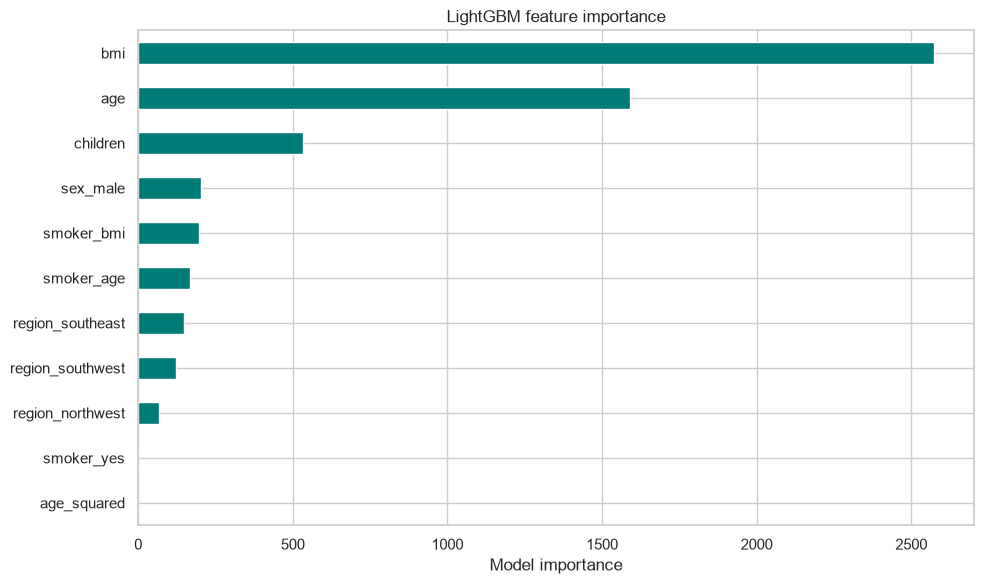

In [25]:
importance = pd.Series(lgb.feature_importances_, index=X_train.columns)
importance.sort_values().plot.barh(color="#007C78", figsize=(10, 6))
plt.title("LightGBM feature importance")
plt.xlabel("Model importance")
plt.tight_layout()
plt.savefig(FIG + "10_lgb_importance.png", dpi=180, bbox_inches="tight")
plt.show()

## 16. Hyperparameter tuning

Try two parameter values per nonlinear model. Fit every candidate on all training rows and compare validation RMSE. These short searches use the validation set rather than cross-validation. Repeated validation comparisons can overfit that split, so keep the test set separate.

### KNN

In [26]:
best_rmse = float("inf")
for k in [5, 15]:
    model = KNeighborsRegressor(n_neighbors=k, weights="distance")
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_val_scaled)
    rmse = root_mean_squared_error(y_val, pred)
    print("k:", k, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        knn_tuned = model

pred_knn_tuned = knn_tuned.predict(X_val_scaled)
evaluate("KNN (tuned)", y_val, pred_knn_tuned)

k: 5 RMSE: 5562.22
k: 15 RMSE: 5263.0
KNN (tuned) RMSE: 5263.0 MAE: 3096.72 R2: 0.771


### MLP

In [27]:
best_rmse = float("inf")
for alpha in [0.001, 0.01]:
    model = MLPRegressor(
        hidden_layer_sizes=(64, 32),
        alpha=alpha,
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=SEED,
    )
    model.fit(X_train_scaled, y_train / 10000)
    pred = model.predict(X_val_scaled) * 10000
    rmse = root_mean_squared_error(y_val, pred)
    print("alpha:", alpha, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        mlp_tuned = model

pred_mlp_tuned = mlp_tuned.predict(X_val_scaled) * 10000
evaluate("MLP (tuned)", y_val, pred_mlp_tuned)

alpha: 0.001 RMSE: 5125.23


alpha: 0.01 RMSE: 5214.08
MLP (tuned) RMSE: 5125.23 MAE: 2950.09 R2: 0.783


### Random Forest

In [28]:
best_rmse = float("inf")
for depth in [4, 8]:
    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=depth,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=2,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, pred)
    print("depth:", depth, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        forest_tuned = model

pred_forest_tuned = forest_tuned.predict(X_val)
evaluate("Random Forest (tuned)", y_val, pred_forest_tuned)

depth: 4 RMSE: 4830.35


depth: 8 RMSE: 4929.96
Random Forest (tuned) RMSE: 4830.35 MAE: 2827.88 R2: 0.807


### XGBoost

In [29]:
best_rmse = float("inf")
for rate in [0.03, 0.05]:
    model = XGBRegressor(
        n_estimators=400,
        max_depth=3,
        learning_rate=rate,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=2,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, pred)
    print("rate:", rate, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        xgb_tuned = model

pred_xgb_tuned = xgb_tuned.predict(X_val)
evaluate("XGBoost (tuned)", y_val, pred_xgb_tuned)

rate: 0.03 RMSE: 4818.37
rate: 0.05 RMSE: 4968.96
XGBoost (tuned) RMSE: 4818.37 MAE: 2675.53 R2: 0.808


### CatBoost

In [30]:
best_rmse = float("inf")
for depth in [3, 5]:
    model = CatBoostRegressor(
        iterations=400,
        depth=depth,
        learning_rate=0.04,
        random_seed=SEED,
        thread_count=2,
        verbose=False,
        allow_writing_files=False,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, pred)
    print("depth:", depth, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        cat_tuned = model

pred_cat_tuned = cat_tuned.predict(X_val)
evaluate("CatBoost (tuned)", y_val, pred_cat_tuned)

depth: 3 RMSE: 4726.58
depth: 5 RMSE: 4795.43
CatBoost (tuned) RMSE: 4726.58 MAE: 2646.97 R2: 0.815


### LightGBM

In [31]:
best_rmse = float("inf")
for leaves in [7, 15]:
    model = LGBMRegressor(
        n_estimators=400,
        num_leaves=leaves,
        learning_rate=0.04,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    rmse = root_mean_squared_error(y_val, pred)
    print("leaves:", leaves, "RMSE:", round(rmse, 2))
    if rmse < best_rmse:
        best_rmse = rmse
        lgb_tuned = model

pred_lgb_tuned = lgb_tuned.predict(X_val)
evaluate("LightGBM (tuned)", y_val, pred_lgb_tuned)

leaves: 7 RMSE: 4816.12


leaves: 15 RMSE: 4991.44
LightGBM (tuned) RMSE: 4816.12 MAE: 2726.51 R2: 0.808


## 17. Model comparison

Compare validation RMSE, MAE, R² and bias for all fitted configurations. A lower validation score can depend on the split. It does not guarantee the same ordering on future data.

,RMSE,MAE,R2,Bias
CatBoost (tuned),4726.58,2646.97,0.82,-52.59
CatBoost,4732.78,2672.06,0.81,6.06
LightGBM (tuned),4816.12,2726.51,0.81,-1.20
XGBoost (tuned),4818.37,2675.53,0.81,-15.09
Random Forest (tuned),4830.35,2827.88,0.81,-68.38
XGBoost,4906.92,2729.23,0.80,27.11
Ridge,4936.85,2882.99,0.80,-183.95
Lasso,4964.28,2902.79,0.80,-173.29
Random Forest,4980.26,2879.96,0.79,205.00
LightGBM,4991.44,2923.20,0.79,8.11


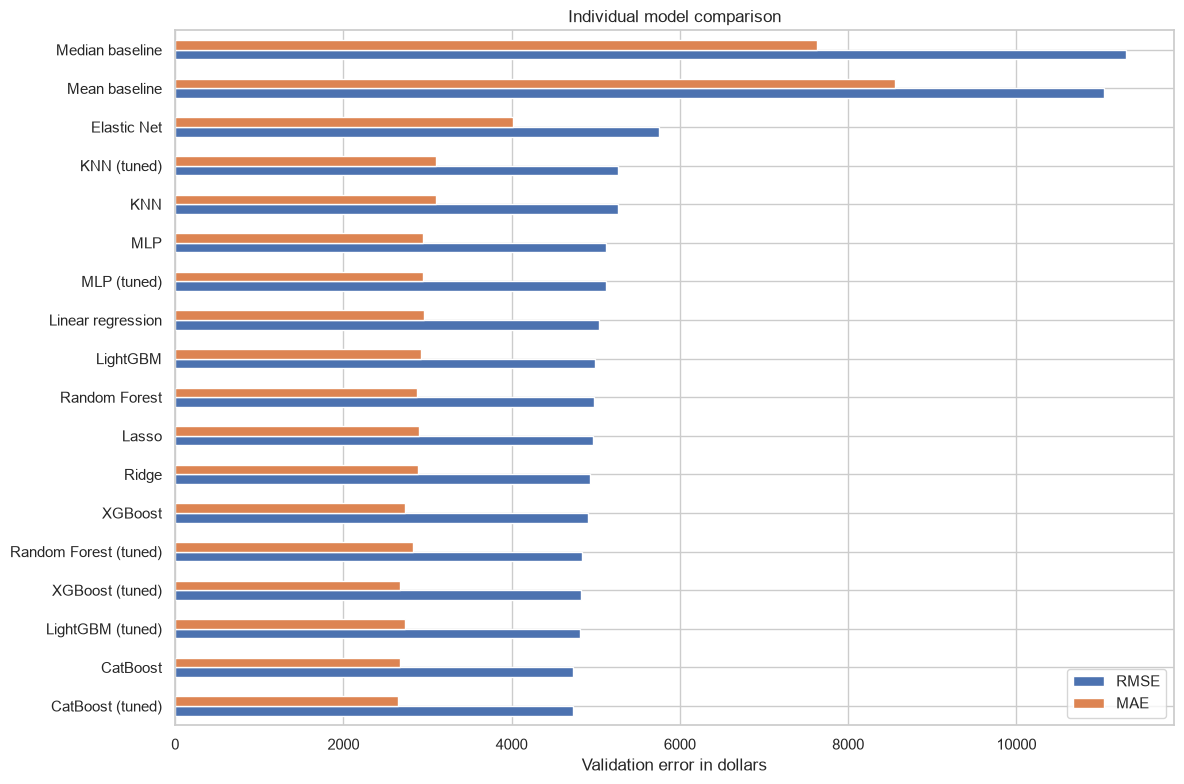

In [32]:
validation_results = pd.DataFrame.from_dict(results, orient="index", columns=["RMSE", "MAE", "R2", "Bias"])
validation_results = validation_results.sort_values("RMSE")
display(validation_results.round(2))

validation_results[["RMSE", "MAE"]].plot.barh(figsize=(12, 8))
plt.xlabel("Validation error in dollars")
plt.title("Individual model comparison")
plt.tight_layout()
plt.savefig(FIG + "11_individual_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 18. Stacking

Combine Random Forest, XGBoost and LightGBM with a Ridge meta-model. `StackingRegressor` creates out-of-fold predictions for the meta-model using three training folds. The base models use unscaled encoded inputs, so there are no learned scaling statistics outside those folds. Evaluate the whole stack on validation data. Stacking adds cost and may provide little gain when the base models make similar errors.

Stacking RMSE: 4906.82 MAE: 2740.76 R2: 0.801


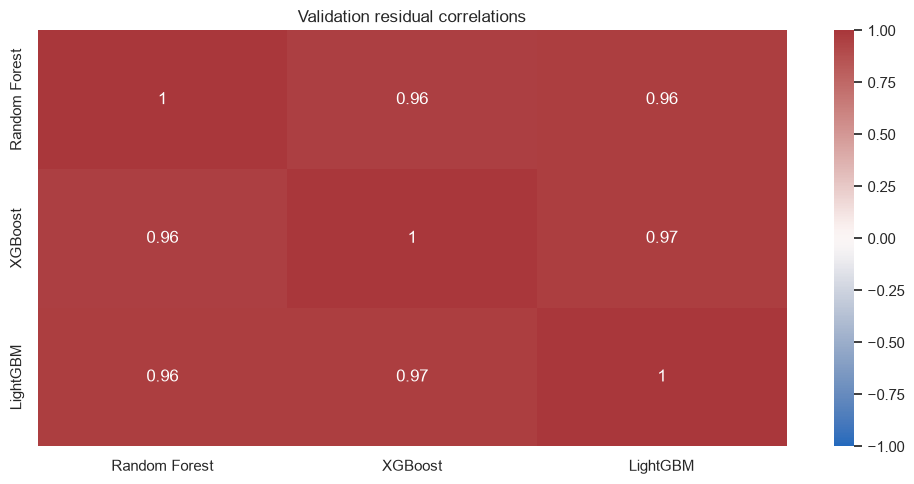

In [33]:
stack = StackingRegressor(
    estimators=[("forest", forest), ("xgboost", xgb), ("lightgbm", lgb)],
    final_estimator=Ridge(alpha=1),
    cv=3,
    n_jobs=2,
)
stack.fit(X_train, y_train)
pred_stack = stack.predict(X_val)
evaluate("Stacking", y_val, pred_stack)

residuals = pd.DataFrame({
    "Random Forest": pred_forest - y_val.to_numpy(),
    "XGBoost": pred_xgb - y_val.to_numpy(),
    "LightGBM": pred_lgb - y_val.to_numpy(),
})
sns.heatmap(residuals.corr(), annot=True, cmap="vlag", vmin=-1, vmax=1)
plt.title("Validation residual correlations")
plt.tight_layout()
plt.savefig(FIG + "12_stack_residual_correlations.png", dpi=180, bbox_inches="tight")
plt.show()

## 19. Feature ablation and log target

Compare the engineered linear model with the original predictors. Remove smoker status and both smoker-derived terms in a separate ablation. Also fit OLS on log charges, then return predictions to dollars. Exponentiating a fitted log expectation does not generally give mean dollar charges, so compare dollar RMSE.

In [34]:
extra_columns = ["age_squared", "smoker_bmi", "smoker_age"]
X_train_original = X_train.drop(columns=extra_columns)
X_val_original = X_val.drop(columns=extra_columns)

original_scaler = StandardScaler()
X_train_original_scaled = original_scaler.fit_transform(X_train_original)
X_val_original_scaled = original_scaler.transform(X_val_original)

lr_original = LinearRegression()
lr_original.fit(X_train_original_scaled, y_train)
pred_original = lr_original.predict(X_val_original_scaled)
evaluate("Linear original features", y_val, pred_original)

Linear original features RMSE: 5806.05 MAE: 3788.98 R2: 0.721


In [35]:
smoker_columns = ["smoker_yes", "smoker_bmi", "smoker_age"]
X_train_no_smoker = X_train.drop(columns=smoker_columns)
X_val_no_smoker = X_val.drop(columns=smoker_columns)

no_smoker_scaler = StandardScaler()
X_train_no_smoker_scaled = no_smoker_scaler.fit_transform(X_train_no_smoker)
X_val_no_smoker_scaled = no_smoker_scaler.transform(X_val_no_smoker)

lr_no_smoker = LinearRegression()
lr_no_smoker.fit(X_train_no_smoker_scaled, y_train)
pred_no_smoker = lr_no_smoker.predict(X_val_no_smoker_scaled)
evaluate("Linear without smoker inputs", y_val, pred_no_smoker)

Linear without smoker inputs RMSE: 10364.68 MAE: 8269.53 R2: 0.111


Linear log target RMSE: 5933.52 MAE: 2852.22 R2: 0.709


,RMSE,MAE,R2,Bias
Linear original features,5806.05,3788.98,0.72,-442.00
Linear regression,5037.49,2955.44,0.79,-66.87
Linear without smoker inputs,10364.68,8269.53,0.11,768.54
Linear log target,5933.52,2852.22,0.71,-471.14


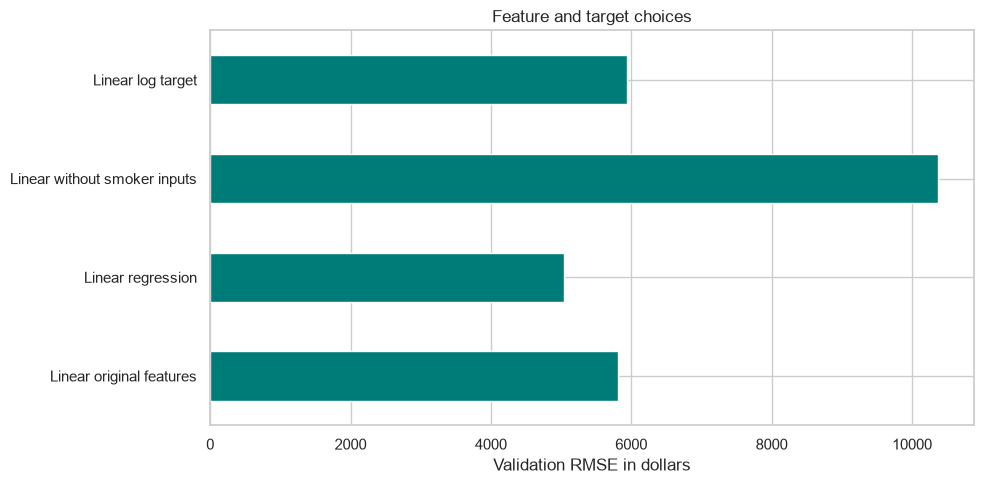

In [36]:
lr_log = LinearRegression()
lr_log.fit(X_train_scaled, np.log1p(y_train))
pred_log = np.expm1(lr_log.predict(X_val_scaled))
evaluate("Linear log target", y_val, pred_log)

validation_results = pd.DataFrame.from_dict(results, orient="index", columns=["RMSE", "MAE", "R2", "Bias"])
validation_results = validation_results.sort_values("RMSE")
ablation_names = ["Linear original features", "Linear regression", "Linear without smoker inputs", "Linear log target"]
display(validation_results.loc[ablation_names].round(2))
validation_results.loc[ablation_names, "RMSE"].plot.barh(color="#007C78")
plt.xlabel("Validation RMSE in dollars")
plt.title("Feature and target choices")
plt.tight_layout()
plt.savefig(FIG + "13_feature_and_target_ablation.png", dpi=180, bbox_inches="tight")
plt.show()

## 20. Final model selection

Read the validation table and choose the final model before scoring test predictions. Refit that chosen model on training plus validation. The model choice below is explicit so it can be reviewed alongside the table.

In [37]:
display(validation_results.head(8).round(2))

best_name = "CatBoost (tuned)"
best_model = cat_tuned
print("Selected model:", best_name)

X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
best_model.fit(X_dev, y_dev)

final_scaler = StandardScaler()
X_dev_scaled = final_scaler.fit_transform(X_dev)
X_test_final_scaled = final_scaler.transform(X_test)
lr_final = LinearRegression()
lr_final.fit(X_dev_scaled, y_dev)

,RMSE,MAE,R2,Bias
CatBoost (tuned),4726.58,2646.97,0.82,-52.59
CatBoost,4732.78,2672.06,0.81,6.06
LightGBM (tuned),4816.12,2726.51,0.81,-1.20
XGBoost (tuned),4818.37,2675.53,0.81,-15.09
Random Forest (tuned),4830.35,2827.88,0.81,-68.38
Stacking,4906.82,2740.76,0.80,7.50
XGBoost,4906.92,2729.23,0.80,27.11
Ridge,4936.85,2882.99,0.80,-183.95


Selected model: CatBoost (tuned)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[-1089.96, 49.32, 899.26,..., -196.87, -386.86, -370.34]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.303e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[55.79,46.68,39.84,..., 9.35, 4.43, 3.35]"


## 21. Final test evaluation

Evaluate the selected model, the development-mean baseline and expanded OLS on the same test records. Plot predictions and residuals. Report negative predictions instead of silently clipping them.

In [38]:
test_prediction = best_model.predict(X_test)
test_mean = np.full(len(y_test), y_dev.mean())
test_lr = lr_final.predict(X_test_final_scaled)

test_predictions = {"Selected model": test_prediction, "Mean baseline": test_mean, "Expanded OLS": test_lr}
test_scores = {}
for name in test_predictions:
    pred = test_predictions[name]
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    bias = np.mean(pred - y_test.to_numpy())
    test_scores[name] = [rmse, mae, r2, bias]

test_results = pd.DataFrame.from_dict(test_scores, orient="index", columns=["RMSE", "MAE", "R2", "Bias"])
display(test_results.round(2))
print("Negative predictions:", (test_prediction < 0).sum())

,RMSE,MAE,R2,Bias
Selected model,4233.33,2410.91,0.90,86.74
Mean baseline,13612.43,9861.80,-0.01,-1241.80
Expanded OLS,4590.58,2890.63,0.89,70.52


Negative predictions: 0


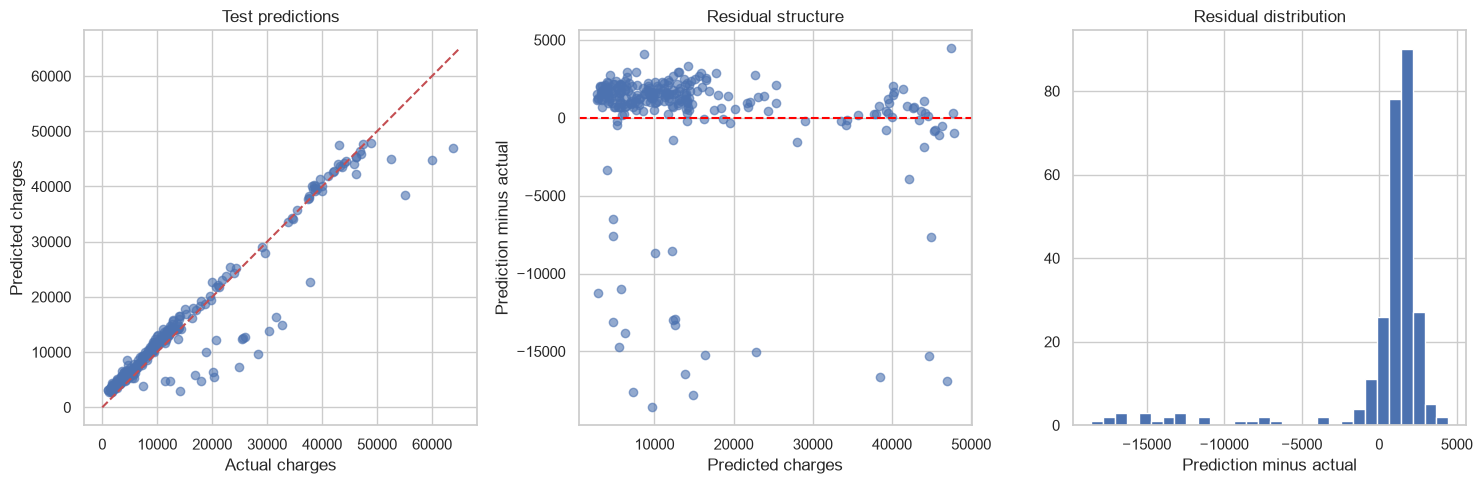

In [39]:
residual = test_prediction - y_test.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].scatter(y_test, test_prediction, alpha=0.6)
axes[0].plot([0, 65000], [0, 65000], "r--")
axes[0].set_xlabel("Actual charges")
axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Test predictions")
axes[1].scatter(test_prediction, residual, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted charges")
axes[1].set_ylabel("Prediction minus actual")
axes[1].set_title("Residual structure")
axes[2].hist(residual, bins=30)
axes[2].set_xlabel("Prediction minus actual")
axes[2].set_title("Residual distribution")
plt.tight_layout()
plt.savefig(FIG + "14_final_test_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

## 22. Model interpretation and error analysis

Compare errors by smoker status, region and charge band, with row counts. Permutation importance measures the fitted model's reliance on each encoded column. Correlated and derived predictors can share importance. Permuting a derived column separately may also create unrealistic combinations, so interpret this diagnostic with care.

,Rows,MAE,Bias
smoker,,,
no,208,2428.43,440.03
yes,60,2350.16,-1137.98


,Rows,MAE,Bias
region,,,
northeast,71,2818.95,-828.91
northwest,60,2504.14,183.14
southeast,77,2302.57,470.73
southwest,60,1973.87,581.08


,Rows,MAE,Bias
charge_band,,,
"(1131.506, 4731.707]",67,1770.94,1770.94
"(4731.707, 9535.651]",67,1349.74,1229.07
"(9535.651, 17781.105]",67,1998.21,861.77
"(17781.105, 63770.428]",67,4524.75,-3514.81


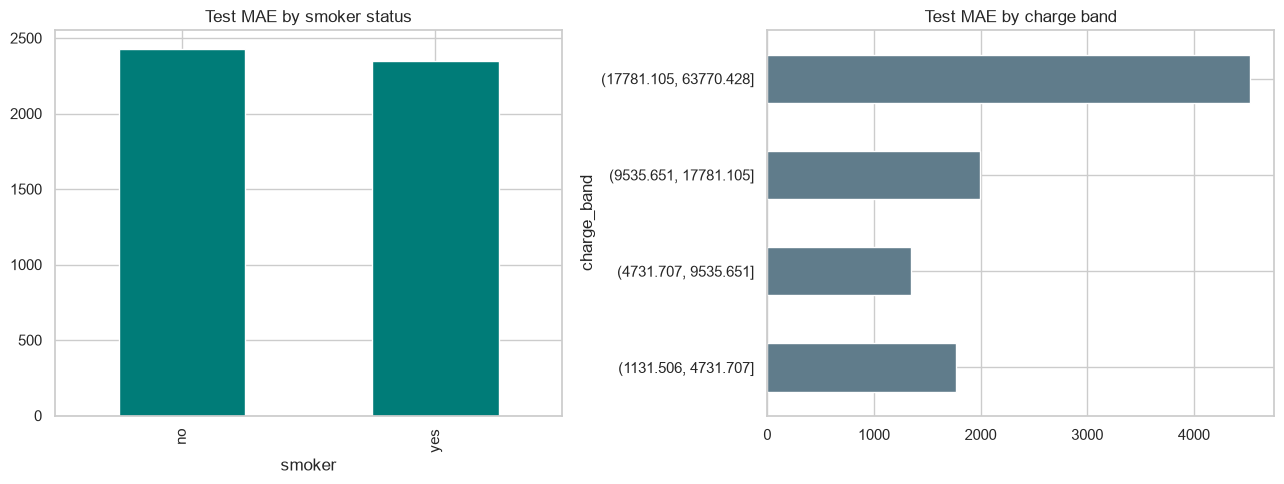

In [40]:
errors = test[["smoker", "region", "charges"]].copy()
errors["prediction"] = test_prediction
errors["error"] = errors["prediction"] - errors["charges"]
errors["absolute_error"] = errors["error"].abs()

smoker_errors = errors.groupby("smoker").agg(
    Rows=("charges", "size"), MAE=("absolute_error", "mean"), Bias=("error", "mean")
)
region_errors = errors.groupby("region").agg(
    Rows=("charges", "size"), MAE=("absolute_error", "mean"), Bias=("error", "mean")
)
errors["charge_band"] = pd.qcut(errors["charges"], 4)
band_errors = errors.groupby("charge_band", observed=True).agg(
    Rows=("charges", "size"), MAE=("absolute_error", "mean"), Bias=("error", "mean")
)
display(smoker_errors.round(2))
display(region_errors.round(2))
display(band_errors.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
smoker_errors["MAE"].plot.bar(ax=axes[0], color="#007C78")
axes[0].set_title("Test MAE by smoker status")
band_errors["MAE"].plot.barh(ax=axes[1], color="#607C8B")
axes[1].set_title("Test MAE by charge band")
plt.tight_layout()
plt.savefig(FIG + "15_group_errors.png", dpi=180, bbox_inches="tight")
plt.show()

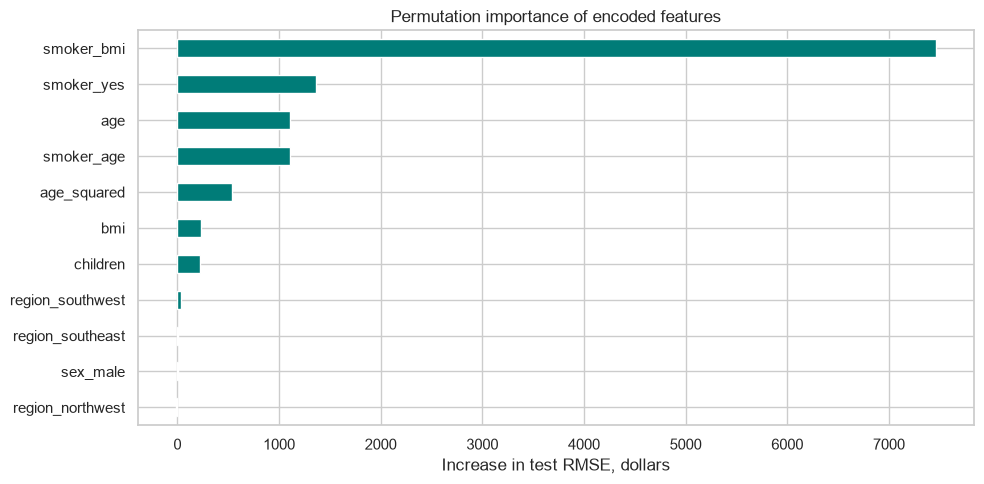

,RMSE increase,Standard deviation
region_northwest,-11.95,7.36
sex_male,9.79,8.95
region_southeast,9.88,7.94
region_southwest,31.91,16.02
children,223.87,48.21
bmi,236.55,62.10
age_squared,537.20,74.67
smoker_age,1103.38,103.19
age,1110.35,103.22
smoker_yes,1365.35,94.05


In [41]:
permutation = permutation_importance(
    best_model, X_test, y_test,
    scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEED, n_jobs=2
)
permutation_results = pd.DataFrame(index=X_test.columns)
permutation_results["RMSE increase"] = permutation.importances_mean
permutation_results["Standard deviation"] = permutation.importances_std
permutation_results = permutation_results.sort_values("RMSE increase")

permutation_results["RMSE increase"].plot.barh(color="#007C78")
plt.title("Permutation importance of encoded features")
plt.xlabel("Increase in test RMSE, dollars")
plt.tight_layout()
plt.savefig(FIG + "16_permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show()
display(permutation_results.round(2))

## 23. Uncertainty and robustness

Resample test rows and recompute RMSE to get a simple bootstrap interval. Use the same sampled rows for the selected model and OLS. This assumes independent test records and holds the fitted models fixed. It does not repeat training or model selection. Repeat outer splits or use external data to assess those additional sources of uncertainty.

,Lower 95%,Upper 95%
Selected model RMSE,3427.83,5000.68
RMSE reduction versus OLS,5.68,656.47


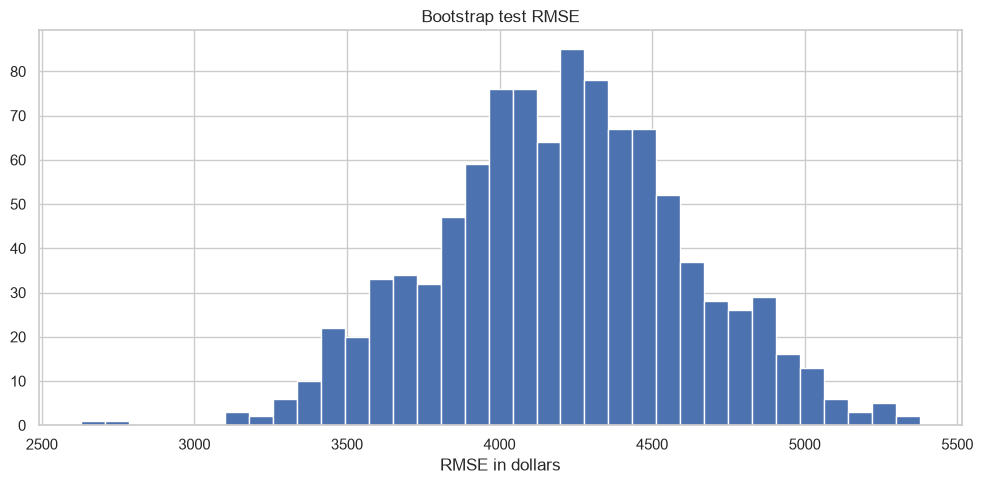

In [42]:
actual = y_test.to_numpy()
bootstrap_rmse = []
bootstrap_difference = []
np.random.seed(SEED)

for i in range(1000):
    sample = np.random.choice(len(actual), size=len(actual), replace=True)
    rmse = root_mean_squared_error(actual[sample], test_prediction[sample])
    lr_rmse = root_mean_squared_error(actual[sample], test_lr[sample])
    bootstrap_rmse.append(rmse)
    bootstrap_difference.append(lr_rmse - rmse)

intervals = pd.DataFrame({
    "Lower 95%": [np.percentile(bootstrap_rmse, 2.5), np.percentile(bootstrap_difference, 2.5)],
    "Upper 95%": [np.percentile(bootstrap_rmse, 97.5), np.percentile(bootstrap_difference, 97.5)],
}, index=["Selected model RMSE", "RMSE reduction versus OLS"])
display(intervals.round(2))

plt.hist(bootstrap_rmse, bins=35)
plt.title("Bootstrap test RMSE")
plt.xlabel("RMSE in dollars")
plt.tight_layout()
plt.savefig(FIG + "17_test_uncertainty.png", dpi=180, bbox_inches="tight")
plt.show()

## 24. Results and conclusion

Summarize the selected model, its error in dollars, the feature experiments and the main limitations. Keep the final model choice based on validation results.

In [43]:
print("Selected model:", best_name)
print("Validation RMSE:", round(validation_results.loc[best_name, "RMSE"], 2))
print("Test RMSE:", round(test_results.loc["Selected model", "RMSE"], 2))
print("Test MAE:", round(test_results.loc["Selected model", "MAE"], 2))
print("Test R2:", round(test_results.loc["Selected model", "R2"], 3))
print("Mean prediction error:", round(test_results.loc["Selected model", "Bias"], 2))

Selected model: CatBoost (tuned)
Validation RMSE: 4726.58
Test RMSE: 4233.33
Test MAE: 2410.91
Test R2: 0.902
Mean prediction error: 86.74


The interaction features let OLS model different age and BMI associations across smoker groups. Compare the feature-ablation table before accepting those extra terms. The log-target model changes the fitting objective, so its dollar error still matters.

This is a small benchmark with limited predictors and incomplete sampling information. Repeated comparisons can overfit a validation split. Demographic profiles may repeat even after exact duplicate removal, and there are no customer identifiers or dates for stronger validation. The bootstrap assumes independent rows. Repeat the experiment on other splits and external data before claiming future accuracy. Feature importance and coefficients do not establish causal effects.

## 25. Presentation questions and saved outputs

Save the tables, predictions and plot images. Use the questions below to prepare for a presentation.

### Questions to prepare for

**Why use RMSE and MAE?** RMSE puts more weight on large misses. MAE is the average absolute error in dollars.

**Why keep valid large charges?** Removing them changes the target population. Check their data quality and report their errors separately.

**Why include Ridge and Lasso?** Ridge can stabilize correlated coefficients. Lasso can remove coefficients. Both can add shrinkage bias. Elastic Net combines the penalties.

**Why standardize some inputs?** Units affect penalties, distances and neural optimization. Trees can split on the original numerical scales.

**Why divide the MLP target by 10,000?** It gives the optimizer smaller numbers. Multiplying predictions by 10,000 returns them to dollars. This fixed unit conversion differs from a nonlinear log transform.

**Why use validation for tuning?** It is a simple way to compare a few settings. Cross-validation would provide a broader assessment. Many repeated validation comparisons can overfit the chosen split.

**Does exponentiating give mean charges?** Generally it does not. A fitted log expectation and a dollar expectation differ. Any correction must use development data.

**How does stacking work?** The meta-model learns from out-of-fold predictions within training. The separate validation set measures the complete stack.

**Why might importance be misleading?** Correlated and derived features can share information. Shuffling one column can create unrealistic combinations. Importance describes the fitted model, not a causal effect.

**What do the uncertainty intervals cover?** They resample test rows with models fixed and assume independent observations. They omit variation from retraining and selection.

**What is the next experiment?** Repeat train/validation/test splits, inspect high-charge errors and test external records with known dates and sampling information.

In [44]:
validation_results.to_csv("outputs/validation_results.csv", index_label="Model")
test_results.to_csv("outputs/test_results.csv", index_label="Model")
smoker_errors.to_csv("outputs/smoker_errors.csv")
region_errors.to_csv("outputs/region_errors.csv")
band_errors.to_csv("outputs/charge_band_errors.csv")
permutation_results.to_csv("outputs/permutation_importance.csv")
intervals.to_csv("outputs/bootstrap_intervals.csv")

validation_predictions = pd.DataFrame(predictions, index=y_val.index)
validation_predictions["actual"] = y_val
validation_predictions.to_csv("outputs/validation_predictions.csv", index_label="source_row")

test_output = pd.DataFrame(index=y_test.index)
test_output["actual"] = y_test
test_output["Selected model"] = np.asarray(test_prediction, dtype=float)
test_output["Mean baseline"] = test_mean
test_output["Expanded OLS"] = test_lr
test_output.to_csv("outputs/test_predictions.csv", index_label="source_row")

split = pd.DataFrame(index=df.index)
split.loc[train.index, "partition"] = "train"
split.loc[val.index, "partition"] = "validation"
split.loc[test.index, "partition"] = "test"
split.to_csv("outputs/split_assignments.csv", index_label="source_row")

### References

- [Kaggle dataset](https://www.kaggle.com/datasets/mirichoi0218/insurance). See `dataset_source.json` and `data_dictionary.csv` for provenance and column definitions.
- [Dataset reference repository](https://github.com/stedy/Machine-Learning-with-R-datasets/blob/master/insurance.csv), associated with *Machine Learning with R* by Brett Lantz.
- [scikit-learn linear models](https://scikit-learn.org/stable/modules/linear_model.html) and [regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).
- [StackingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingRegressor.html), [XGBoost](https://xgboost.readthedocs.io/), [CatBoost](https://catboost.ai/docs/) and [LightGBM](https://lightgbm.readthedocs.io/).